# Libaries and Preamble

In [1]:
import pandas as pd
import numpy as np
from functions import read_squid_file
import matplotlib.pyplot as plt
import os

In [2]:
#=======================================================================
# matplotlib rc — academic / journal style
#=======================================================================
plt.rcParams.update({
    "font.family":       "serif",
    "font.size":         10,
    "axes.labelsize":    10,
    "axes.titlesize":    10,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
    "legend.fontsize":   9,
    "lines.linewidth":   1.0,
    "axes.linewidth":    0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5,
    "xtick.major.size":  4.0,
    "ytick.major.size":  4.0,
    "xtick.minor.size":  2.0,
    "ytick.minor.size":  2.0,
    "xtick.direction":   "in",
    "ytick.direction":   "in",
    "xtick.top":         True,
    "ytick.right":       True,
    "axes.grid":         True,
    "grid.color":        "#CCCCCC",
    "grid.linewidth":    0.4,
    "grid.linestyle":    "--",
    "grid.alpha":        0.6,
    "axes.axisbelow":    True,
    "figure.facecolor":  "white",
    "axes.facecolor":    "white",
    "savefig.dpi":       600,
    "savefig.bbox":      "tight",
    "savefig.facecolor": "white",
    "figure.dpi":        150,
    "legend.framealpha": 0.9,
    "legend.edgecolor":  "#AAAAAA",
    "legend.frameon":    True,
})

In [5]:
pb = read_squid_file(
    r"C:\Users\olive\OneDrive - University of Bristol\Final Project\Data\Ollie_and_Ben\2026\10\FeSe_bo001_MvsT_FW_VariousFields\2026-10-22_FeSe_bo001_MvsT_FW_Various_Field_00001.dat"
)
pb.head()

,Time Stamp (sec),Temperature (K),Magnetic Field (Oe),Moment (emu),M. Std. Err. (emu),Transport Action,Center Position (mm),AC Susceptibility (emu/Oe),AC Suscept. Std Err. (emu/Oe),AC X' (emu/Oe),...,DC Free Fit,DC Calculated Center (mm),DC Calculated Center Err (mm),DC Scan Length (mm),DC Scan Time (s),DC Number of Points,DC Squid Drift,DC Min V (V),DC Max V (V),DC Scans per Measure
0,4.001867e+09,1.997777,9.543491,NaN,NaN,6,27.459717,NaN,NaN,NaN,...,0.987620,28.745184,0.000000e+00,40,1,200,-0.000153,-0.912385,1.641569,1
1,4.001867e+09,2.009421,9.543491,NaN,NaN,6,27.459717,NaN,NaN,NaN,...,0.987514,28.748537,1.173216e-17,40,1,200,0.001000,-0.911277,1.642448,1
2,4.001867e+09,2.026711,9.543491,NaN,NaN,6,27.459717,NaN,NaN,NaN,...,0.985760,28.739580,9.911887e-35,40,1,200,0.001367,-0.910724,1.642557,1
3,4.001867e+09,2.034286,9.543491,NaN,NaN,6,27.459717,NaN,NaN,NaN,...,0.986241,28.746519,0.000000e+00,40,1,200,0.000774,-0.910484,1.642952,1
4,4.001867e+09,2.056639,9.543491,NaN,NaN,6,27.459717,NaN,NaN,NaN,...,0.987009,28.740274,1.618305e-17,40,1,200,0.000971,-0.910180,1.642816,1


Text(0.5, 0, 'Temperature (K)')

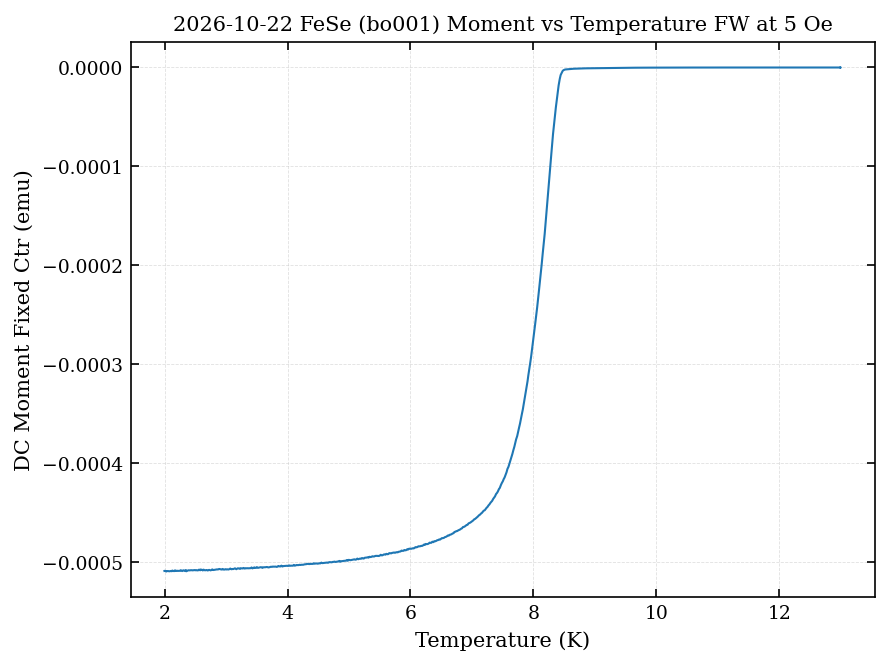

In [18]:
plt.plot(pb["Temperature (K)"],pb["DC Moment Fixed Ctr (emu)"])
plt.title("2026-10-22 FeSe (bo001) Moment vs Temperature FW at 5 Oe")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.xlabel("Temperature (K)")

### Current Plan for Data Analysis 
- we need a method for looping throught a set number of files
- easiest way is to make a folder for the data 
- and then loop throught the folder and get all the raw data 


In [8]:
# Source - https://stackoverflow.com/a/10378012
# Posted by anselm, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-15, License - CC BY-SA 4.0
# edited by ben thomposn

from pathlib import Path
runs = {}
pathlist = Path(
    r"C:\Users\olive\OneDrive - University of Bristol\Final Project\Data\Ollie_and_Ben\2026\10\FeSe_bo001_MvsT_FW_VariousFields"
).glob("**/*.dat")
for path in sorted(pathlist):
    run_number = path.stem[-5:]
    runs[run_number] = read_squid_file(str(path))
for run_number, data in runs.items():
    print(f"Run {run_number}")

Run 00001
Run 00002
Run 00003
Run 00004
Run 00005


In [9]:
field_column = "Magnetic Field (Oe)"
field_labels = {}

for run_number, dataframe in runs.items():
    mean_field = dataframe[field_column].mean()
    field_labels[run_number] = f"{mean_field:.0f} Oe"

In [10]:
for run_number, dataframe in runs.items():
    print(f"Run {run_number}")
    print(dataframe.head())
    print("="*80)

Run 00001
   Time Stamp (sec)  Temperature (K)  Magnetic Field (Oe)  Moment (emu)  \
0      4.001867e+09         1.997777             9.543491           NaN   
1      4.001867e+09         2.009421             9.543491           NaN   
2      4.001867e+09         2.026711             9.543491           NaN   
3      4.001867e+09         2.034286             9.543491           NaN   
4      4.001867e+09         2.056639             9.543491           NaN   

   M. Std. Err. (emu)  Transport Action  Center Position (mm)  \
0                 NaN                 6             27.459717   
1                 NaN                 6             27.459717   
2                 NaN                 6             27.459717   
3                 NaN                 6             27.459717   
4                 NaN                 6             27.459717   

   AC Susceptibility (emu/Oe)  AC Suscept. Std Err. (emu/Oe)  AC X' (emu/Oe)  \
0                         NaN                            NaN        

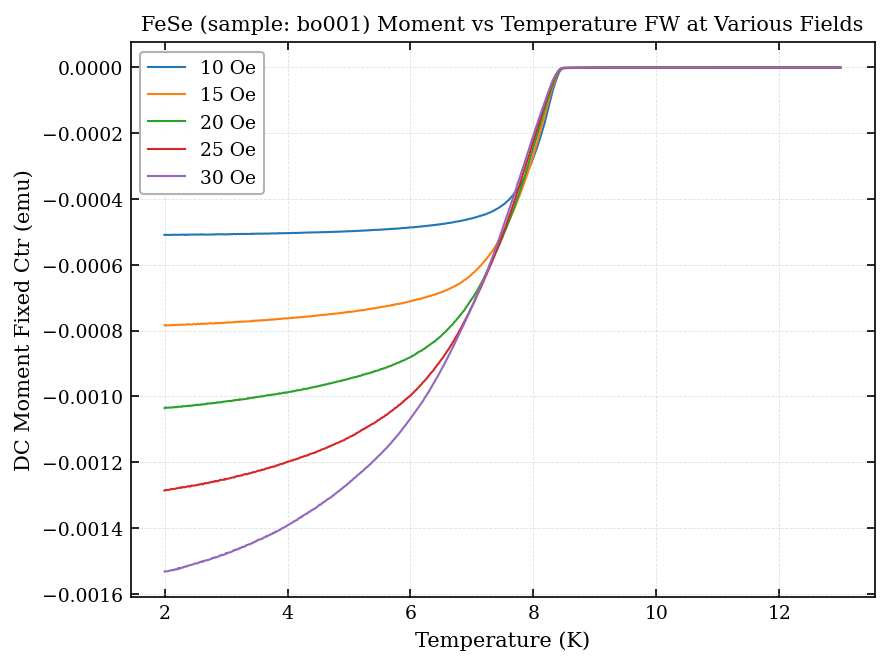

In [19]:

for run_number, dataframe in runs.items():
    plt.plot(
        dataframe["Temperature (K)"],
        dataframe["DC Moment Fixed Ctr (emu)"],
        label=field_labels[run_number],
    )

plt.title("FeSe (sample: bo001) Moment vs Temperature FW at Various Fields")
plt.xlabel("Temperature (K)")
plt.ylabel("DC Moment Fixed Ctr (emu)")
plt.legend()
plt.show()

Run 00001: mean field = 9.54 Oe, Tc = 8.4284 K
Run 00002: mean field = 14.62 Oe, Tc = 8.4240 K
Run 00003: mean field = 19.64 Oe, Tc = 8.4202 K
Run 00004: mean field = 24.61 Oe, Tc = 8.4193 K
Run 00005: mean field = 29.77 Oe, Tc = 8.4190 K


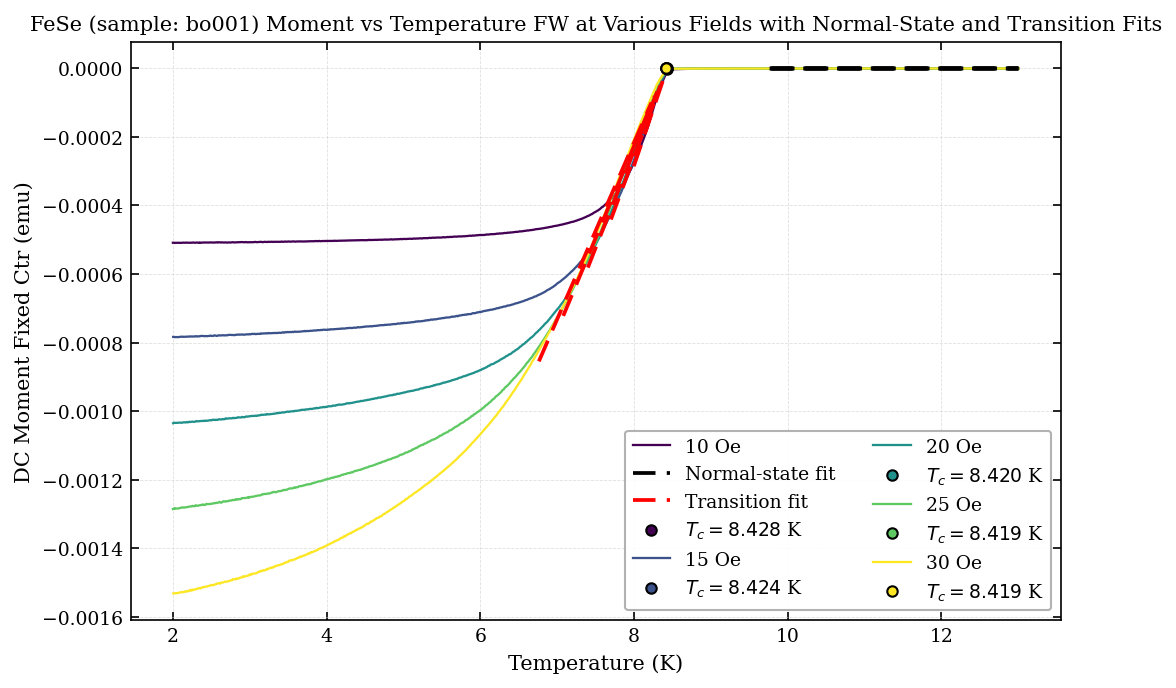

,Mean field (Oe),Tc (K),Moment at Tc (emu),normal_slope,normal_intercept,transition_slope,transition_intercept
00001,9.543491,8.428435,-1.709904e-07,3.447192e-08,-4.615347e-07,0.000660,-0.005560
00002,14.619817,8.423963,-1.365453e-07,2.588824e-08,-3.546269e-07,0.000607,-0.005116
00003,19.636421,8.420248,-1.209817e-07,2.206217e-08,-3.067506e-07,0.000569,-0.004788
00004,24.605246,8.419252,-1.055573e-07,1.842352e-08,-2.606695e-07,0.000538,-0.004532
00005,29.765182,8.419009,-9.096639e-08,1.495598e-08,-2.168809e-07,0.000515,-0.004339


In [21]:
# Git Copilot 5.6 Luna usgeenrateed to  example code structure for fitting normal-state and transition regions of MvsT data. Code modified by Ollie Pentecost to suit Pb data.

temperature_column = "Temperature (K)"
moment_column = "DC Moment Fixed Ctr (emu)"
field_column = "Magnetic Field (Oe)"

fit_results = {}
fig, ax = plt.subplots(figsize=(8, 5))
colors = plt.get_cmap("viridis", len(runs))

tc_list = []
mean_field_list = []

for plot_index, (run_number, dataframe) in enumerate(runs.items()):
    data = dataframe[[temperature_column, moment_column]].dropna()
    data = data.sort_values(temperature_column)
    data = data.drop_duplicates(subset=temperature_column)

    temperature = data[temperature_column].to_numpy()
    moment = data[moment_column].to_numpy()
    colour = colors(plot_index)

    mean_field = dataframe[field_column].mean()
    field_label = f"{mean_field:.0f} Oe"

    # Normalise moment between the low- and high-temperature limits
    m_low, m_high = np.percentile(moment, [5, 95])
    moment_norm = (moment - m_low) / (m_high - m_low)

    normal_mask = (
        (moment_norm >= 0.75)
        & (temperature >= np.percentile(temperature, 70))
    )
    transition_mask = (
        (moment_norm >= 0.45)
        & (moment_norm <= 0.95)
    )

    normal_m, normal_c = np.polyfit(
        temperature[normal_mask],
        moment[normal_mask],
        1,
    )
    transition_m, transition_c = np.polyfit(
        temperature[transition_mask],
        moment[transition_mask],
        1,
    )

    tc = (transition_c - normal_c) / (normal_m - transition_m)
    tc_list.append(tc)
    mc = normal_m * tc + normal_c
    mean_field_list.append(mean_field)
    fit_results[run_number] = {
        "Mean field (Oe)": mean_field,
        "Tc (K)": tc,
        "Moment at Tc (emu)": mc,
        "normal_slope": normal_m,
        "normal_intercept": normal_c,
        "transition_slope": transition_m,
        "transition_intercept": transition_c,
    }

    ax.plot(
        temperature,
        moment,
        color=colour,
        linewidth=1.1,
        label=field_label,
        zorder=2,
    )

    normal_x = np.linspace(
        temperature[normal_mask].min(),
        temperature[normal_mask].max(),
        100,
    )
    transition_x = np.linspace(
        temperature[transition_mask].min(),
        temperature[transition_mask].max(),
        100,
    )

    ax.plot(
        normal_x,
        normal_m * normal_x + normal_c,
        color="black",
        linestyle=(0, (6, 3)),
        linewidth=1.8,
        label="Normal-state fit" if plot_index == 0 else "_nolegend_",
        zorder=5,
    )
    ax.plot(
        transition_x,
        transition_m * transition_x + transition_c,
        color="red",
        linestyle=(0, (6, 3)),
        linewidth=1.8,
        label="Transition fit" if plot_index == 0 else "_nolegend_",
        zorder=5,
    )
    ax.plot(
        tc,
        mc,
        "o",
        color=colour,
        markersize=5,
        markeredgecolor="black",
        label=fr"$T_c={tc:.3f}$ K",
        zorder=6,
    )

    print(f"Run {run_number}: mean field = {mean_field:.2f} Oe, Tc = {tc:.4f} K")

ax.set_title("FeSe (sample: bo001) Moment vs Temperature FW at Various Fields with Normal-State and Transition Fits")
ax.set_xlabel("Temperature (K)")
ax.set_ylabel(moment_column)
ax.legend(ncol=2)
plt.show()

pd.DataFrame(fit_results).T

Tc0² = 71.11 ± 23.66 K²
Hc0 = 7750.96 ± 1821.12 Oe
Tc0 = 8.43 ± 1.40 K


Text(0.5, 0, 'Critical Temperature Squared (Tc²)')

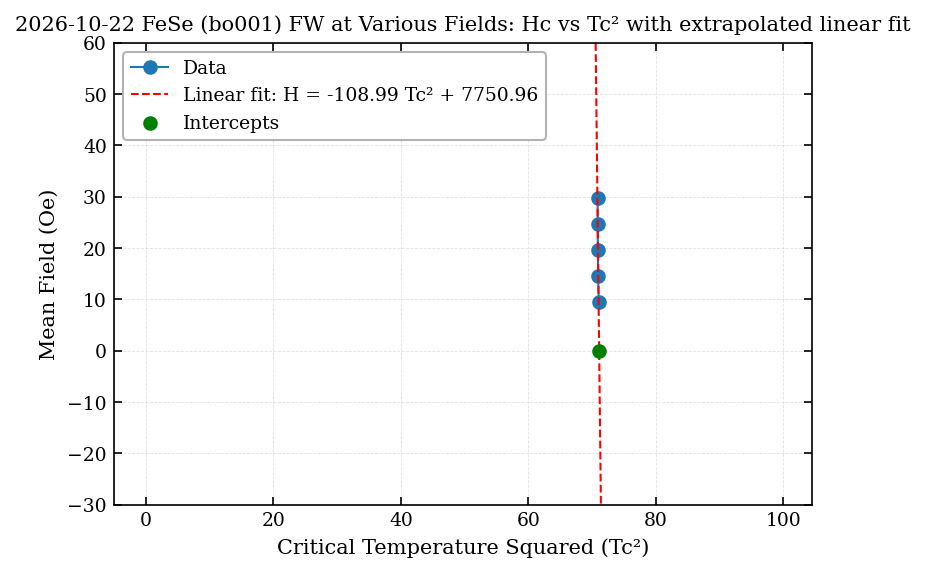

In [23]:
tc_array = np.array(tc_list)
tcsqrd = tc_array ** 2
field_array = np.array(mean_field_list)

(m, c), cov = np.polyfit(tcsqrd, field_array, 1, cov=True)
m_err, c_err = np.sqrt(np.diag(cov))

Hc0 = c
Tc0_sqrd = -c / m
Tc0 = np.sqrt(Tc0_sqrd)

Hc0_err = c_err
Tc0__sq_err = Tc0_sqrd * np.sqrt((m_err / m) ** 2 + (c_err / c) ** 2)
Tc0_err = 0.5 * Tc0 * (Tc0__sq_err / Tc0_sqrd)

print(f"Tc0\u00b2 = {Tc0_sqrd:.2f} ± {Tc0__sq_err:.2f} K\u00b2")
print(f"Hc0 = {Hc0:.2f} ± {Hc0_err:.2f} Oe")
print(f"Tc0 = {Tc0:.2f} ± {Tc0_err:.2f} K")

#extrapolate the line
x_fit = np.linspace(0, tcsqrd.max() * 1.4, 100)

plt.figure(figsize=(6, 4))
plt.plot(tcsqrd, field_array, "o-", label="Data")
plt.plot(x_fit, m * x_fit + c, "r--", label=f"Linear fit: H = {m:.2f} Tc² + {c:.2f}")
plt.scatter([0, Tc0_sqrd], [Hc0, 0], color="green", zorder=3, label="Intercepts")
plt.legend()
#plt.xlim(left=0)
plt.ylim(top=60, bottom=-30)
plt.title("2026-10-22 FeSe (bo001) FW at Various Fields: Hc vs Tc\u00b2 with extrapolated linear fit")
plt.ylabel("Mean Field (Oe)")
plt.xlabel("Critical Temperature Squared (Tc\u00b2)")